In [1]:
#### CORRECTIONS REBUILT ON EACH BINNING'S OWN TEFF GRID ####
# The two cells at the end of reviewer_report1_statistical_analysis.ipynb rebin the
# planets three ways and refit the model ladder, but every planet keeps the weight it
# was given on the 500 K completeness grid. A 250 K bin therefore inherits the
# detection rate of its parent 500 K slice, and a shifted bin straddles two slices and
# mixes them. The referee asked for the corrections to be recalculated for the new
# bins, not just regrouped, so this notebook does that: the injection/recovery results
# are re-aggregated into master heatmaps on each binning's own Teff grid, and the whole
# analysis is run again against those.
#
#   native_250K/      15 slices, 3250-7000 K in 250 K steps
#   native_shifted/    8 slices, 3250-7250 K in 500 K steps
#
# Both were produced by heatmaps_analysis_random_injections.ipynb with only temp_ranges
# changed, so they share that notebook's transit probability, the grazing-exclusive
# (R_star - R_planet) / a, with the master_heatmap*.csv in this directory that the
# inherited side reads. Holding the formula fixed across all three leaves the Teff
# resolution of the correction as the only thing that differs between the rows.
#
# There are no injected stars below 3250 K, so the 3000-3250 K bin has no native slice
# at all and its planets fall through uncorrected. That is reported rather than hidden.

import glob
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

n_bootstrap_fit = 1000

bins_500 = list(range(3000, 7001, 500))
bins_half = list(range(3000, 7001, 250))
bins_shifted = list(range(3250, 7251, 500))


def teff_ranges_from(edges):
    ranges = []
    for i in range(len(edges) - 1):
        ranges.append((edges[i], edges[i + 1]))
    return ranges


def load_completeness(directory):
    # One master heatmap CSV per Teff slice, stacked with the slice recorded per row
    completeness = pd.DataFrame()
    for f in sorted(glob.glob(os.path.join(directory, 'master_heatmap*.csv'))):
        match = re.search(r'(\d{4})_(\d{4})_K', os.path.basename(f))
        slice_df = pd.read_csv(f)
        slice_df['teff_bin'] = f"{match.group(1)}_{match.group(2)}"
        completeness = pd.concat([completeness, slice_df], ignore_index=True)
    return completeness


def log_edges(centers):
    # Bin edges halfway between the centres in log space, extrapolated at both ends,
    # the same construction the main notebook uses for the radius and period grids
    centers = np.array(sorted(centers))
    logs = np.log10(centers)
    edges = [10 ** (logs[0] - (logs[1] - logs[0]) / 2)]
    for i in range(len(logs) - 1):
        edges.append(10 ** ((logs[i] + logs[i + 1]) / 2))
    edges.append(10 ** (logs[-1] + (logs[-1] - logs[-2]) / 2))
    return np.array(edges)


def cell_index(values, edges):
    # Which grid cell each value falls in, NaN when it falls off the grid entirely
    inside = (values >= edges[0]) & (values < edges[-1])
    return np.where(inside, np.searchsorted(edges, values, side='right') - 1, np.nan)


def load_tois():
    TOIs = pd.read_csv('../TOI_Mar2025_1pt5to4_R_detected_real_only.csv')
    TOIs = TOIs.dropna(subset=['st_teff', 'pl_rade'])
    TOIs = TOIs[(TOIs['pl_rade'] > 1.8) & (TOIs['pl_rade'] < 4.0)]
    TOIs = TOIs[(TOIs['pl_orbper'] > 0.6028) & (TOIs['pl_orbper'] < 25.1)]
    TOIs = TOIs[TOIs['st_tmag'] < 13]
    if 'tfopwg_disp' in TOIs.columns:
        TOIs = TOIs[TOIs['tfopwg_disp'] != 'FP']
    return TOIs[['toi', 'st_teff', 'pl_rade', 'pl_orbper']].copy()


def build_weights(completeness, teff_ranges):
    # Match every TOI to its own (Teff slice, radius cell, period cell) and weight it
    # by 1/detection_rate * 1/transit_prob for that cell, exactly as the main notebook
    # does -- the only thing that changes here is which Teff grid the slices live on.
    radius_edges = log_edges(completeness['radius_bin_center'].unique())
    period_edges = log_edges(completeness['period_bin_center'].unique())

    completeness = completeness.copy()

    # A cell with no detections is not completeness zero, it is completeness
    # unmeasured: 0 detections in n trials only bounds the rate above, at about 1/n.
    # This matters because a rate of exactly zero makes the weight infinite, and the
    # isfinite filter inside wmedian would then drop that planet without saying so --
    # at 500 K the cells are thick enough that no TOI ever lands in one, but the
    # native slices have a handful of cells with only three or four trials.
    floored = (completeness['detection_rate'] == 0)
    completeness.loc[floored, 'detection_rate'] = 1 / completeness.loc[floored, 'trials']
    if floored.sum():
        print(f"  floored {floored.sum()} zero-detection cells to 1/trials "
              f"(trials {sorted(completeness.loc[floored, 'trials'].unique())})")
    completeness['radius_cell'] = cell_index(completeness['radius_bin_center'].values, radius_edges)
    completeness['period_cell'] = cell_index(completeness['period_bin_center'].values, period_edges)

    planets = load_tois()

    teff_bins = []
    for teff in planets['st_teff']:
        found = np.nan
        for teff_min, teff_max in teff_ranges:
            if teff_min <= teff < teff_max:
                found = f"{teff_min}_{teff_max}"
        teff_bins.append(found)
    planets['teff_bin'] = teff_bins
    planets['radius_cell'] = cell_index(planets['pl_rade'].values, radius_edges)
    planets['period_cell'] = cell_index(planets['pl_orbper'].values, period_edges)

    planets = pd.merge(
        planets,
        completeness[['teff_bin', 'radius_cell', 'period_cell', 'detection_rate', 'transit_prob']],
        on=['teff_bin', 'radius_cell', 'period_cell'], how='left')

    # A planet with no cell keeps weight 1, which quietly means "needs no correction".
    # Count those rather than letting them hide inside a median.
    planets['weight'] = (1 / planets['detection_rate'] * 1 / planets['transit_prob']).fillna(1)
    matched = planets['detection_rate'].notna().sum()
    print(f"  completeness match: {matched}/{len(planets)} "
          f"({100 * matched / len(planets):.1f}%), {len(planets) - matched} uncorrected")
    assert np.isfinite(planets['weight']).all(), "infinite weight would be dropped silently"
    return planets


# Weights on the 500 K grid, which is what the last two cells of the main notebook use
# for all three binnings, so this row is the thing the rows below are compared against
print("Inherited corrections, 500 K slices")
planets_inherited = build_weights(load_completeness('.'), teff_ranges_from(bins_500))

print("Native corrections, 250 K slices")
planets_native_half = build_weights(load_completeness('native_250K'), teff_ranges_from(bins_half))

print("Native corrections, shifted 500 K slices")
planets_native_shifted = build_weights(load_completeness('native_shifted'), teff_ranges_from(bins_shifted))

# How much the correction itself moves when it is rebuilt at the finer resolution
print("\nMean detection rate per Teff slice, inherited parent vs native slice")
print("-" * 72)
native_half = load_completeness('native_250K')
inherited = load_completeness('.')
for teff_bin in sorted(native_half['teff_bin'].unique()):
    low = int(teff_bin.split('_')[0])
    parent = f"{low // 500 * 500}_{low // 500 * 500 + 500}"
    if parent not in set(inherited['teff_bin']):
        continue
    native_rate = native_half.loc[native_half['teff_bin'] == teff_bin, 'detection_rate'].mean()
    parent_rate = inherited.loc[inherited['teff_bin'] == parent, 'detection_rate'].mean()
    print(f"  {teff_bin.replace('_', '-'):>12} K: native={native_rate:.3f}, "
          f"parent {parent.replace('_', '-')} K={parent_rate:.3f}, "
          f"ratio={native_rate / parent_rate:.3f}")

Inherited corrections, 500 K slices
  floored 2 zero-detection cells to 1/trials (trials [16, 20])
  completeness match: 672/673 (99.9%), 1 uncorrected
Native corrections, 250 K slices
  floored 11 zero-detection cells to 1/trials (trials [3, 4, 5, 9, 10, 11])
  completeness match: 669/673 (99.4%), 4 uncorrected
Native corrections, shifted 500 K slices
  floored 9 zero-detection cells to 1/trials (trials [3, 4, 5, 9, 10])
  completeness match: 669/673 (99.4%), 4 uncorrected

Mean detection rate per Teff slice, inherited parent vs native slice
------------------------------------------------------------------------
     3250-3500 K: native=0.838, parent 3000-3500 K=0.838, ratio=1.000
     3500-3750 K: native=0.731, parent 3500-4000 K=0.753, ratio=0.972
     3750-4000 K: native=0.786, parent 3500-4000 K=0.753, ratio=1.044
     4000-4250 K: native=0.759, parent 4000-4500 K=0.784, ratio=0.968
     4250-4500 K: native=0.806, parent 4000-4500 K=0.784, ratio=1.028
     4500-4750 K: native=0.8

In [2]:
#### CORRECTED MEDIANS, INHERITED AGAINST NATIVE ####
# Same weighted median and same seeded bootstrap as the main notebook, run twice per
# binning: once on the inherited 500 K weights and once on the weights rebuilt at the
# binning's own resolution. The 500 K baseline is the same thing both ways and is kept
# only as a check that the machinery here reproduces the cells it is being compared to.


def wmedian(vals, weights):
    # Value where the sorted cumulative weight passes half
    vals = np.asarray(vals, dtype=float)
    weights = np.asarray(weights, dtype=float)
    keep = np.isfinite(vals) & np.isfinite(weights) & (weights > 0)
    if keep.sum() == 0:
        return np.nan
    vals, weights = vals[keep], weights[keep]
    order = np.argsort(vals)
    vals, weights = vals[order], weights[order]
    return float(vals[np.searchsorted(np.cumsum(weights), 0.5 * weights.sum())])


def corrected_medians(planets, edges):
    # Completeness-corrected weighted median radius per Teff bin, with bootstrap
    # errors. Reseeded per call so the two corrections are compared on the same draws.
    planets = planets.dropna(subset=['st_teff', 'pl_rade', 'weight'])
    rng = np.random.default_rng(11)

    centers = []
    medians = []
    errors = []
    counts = []
    no_cell = []

    for i in range(len(edges) - 1):
        bin_mask = (planets['st_teff'] >= edges[i]) & (planets['st_teff'] < edges[i + 1])
        radii = planets.loc[bin_mask, 'pl_rade'].values
        weights = planets.loc[bin_mask, 'weight'].values

        centers.append((edges[i] + edges[i + 1]) / 2)
        counts.append(len(radii))
        no_cell.append(int(planets.loc[bin_mask, 'detection_rate'].isna().sum()))

        if len(radii) == 0 or np.nansum(weights) <= 0:
            medians.append(np.nan)
            errors.append(np.nan)
            continue

        bootstrap_medians = []
        for _ in range(n_bootstrap_fit):
            pick = rng.integers(0, len(radii), size=len(radii))
            bootstrap_medians.append(wmedian(radii[pick], weights[pick]))

        medians.append(wmedian(radii, weights))
        errors.append(np.nanstd(bootstrap_medians))

    return (np.array(centers), np.array(medians), np.array(errors),
            np.array(counts), np.array(no_cell))


def usable(medians, errors, counts, no_cell):
    # A bin needs a median, a real error bar, and at least two planets behind it.
    # One planet makes every bootstrap resample identical, so the error comes back as
    # rounding noise (~1e-16) rather than exactly zero -- it survives an `errors == 0`
    # test and then contributes ~1e30 to chi2, which drags every fit onto that one bin.
    # Bins whose planets all lack a completeness cell are dropped for the same reason
    # the 3000-3250 K bin is: an uncorrected median does not belong among corrected ones.
    good = ~(np.isnan(medians) | np.isnan(errors))
    good = good & (errors > 1e-12) & (counts >= 2)
    return good & ~(no_cell == counts)


# The three binnings, each with the planets weighted both ways
tests = {
    '500 K baseline': {'edges': bins_500, 'native': planets_inherited, 'color': 'forestgreen'},
    'Half-width 250 K': {'edges': bins_half, 'native': planets_native_half, 'color': 'darkviolet'},
    'Shifted by 250 K': {'edges': bins_shifted, 'native': planets_native_shifted, 'color': 'teal'},
}

for name, test in tests.items():
    centers, medians, errors, counts, no_cell = corrected_medians(planets_inherited, test['edges'])
    good_inherited = usable(medians, errors, counts, no_cell)
    test['x_inherited'] = centers[good_inherited]
    test['y_inherited'] = medians[good_inherited]
    test['yerr_inherited'] = errors[good_inherited]

    centers, medians_native, errors_native, counts, no_cell = corrected_medians(test['native'], test['edges'])
    good = usable(medians_native, errors_native, counts, no_cell)
    test['x'] = centers[good]
    test['y'] = medians_native[good]
    test['yerr'] = errors_native[good]
    test['no_cell'] = no_cell

    print(f"\n{name}: {len(test['edges']) - 1} bins")
    print("-" * 86)
    print(f"  {'Teff (K)':<14}{'N':>4}{'inherited':>21}{'native':>21}{'shift':>10}")
    for i in range(len(centers)):
        warn = f"  *** {no_cell[i]} with no completeness cell ***" if no_cell[i] else ""
        if not good[i]:
            print(f"  {test['edges'][i]}-{test['edges'][i+1]:<8} {counts[i]:>4}  dropped{warn}")
            continue
        print(f"  {test['edges'][i]}-{test['edges'][i+1]:<8} {counts[i]:>4}"
              f"{medians[i]:>13.2f} +/-{errors[i]:>5.3f}"
              f"{medians_native[i]:>13.2f} +/-{errors_native[i]:>5.3f}"
              f"{medians_native[i] - medians[i]:>+10.3f}{warn}")

    # Compare only the bins that survive in both, so a bin dropped for having no
    # native slice does not masquerade as a shift
    both = good & good_inherited
    shifts = medians_native[both] - medians[both]
    biggest = np.argmax(np.abs(shifts))
    print(f"  Largest shift: {shifts[biggest]:+.3f} R_Earth at "
          f"{test['edges'][np.flatnonzero(both)[biggest]]} K, "
          f"median error on these bins: {np.median(errors_native[both]):.3f} R_Earth")


500 K baseline: 8 bins
--------------------------------------------------------------------------------------
  Teff (K)         N            inherited               native     shift
  3000-3500       31         2.10 +/-0.130         2.10 +/-0.130    +0.000
  3500-4000       79         2.25 +/-0.050         2.25 +/-0.050    +0.000
  4000-4500       73         2.64 +/-0.122         2.64 +/-0.122    +0.000
  4500-5000       84         2.41 +/-0.113         2.41 +/-0.113    +0.000
  5000-5500      121         2.45 +/-0.057         2.45 +/-0.057    +0.000
  5500-6000      168         2.50 +/-0.077         2.50 +/-0.077    +0.000  *** 1 with no completeness cell ***
  6000-6500       99         2.44 +/-0.060         2.44 +/-0.060    +0.000
  6500-7000       18         2.80 +/-0.126         2.80 +/-0.126    +0.000
  Largest shift: +0.000 R_Earth at 3000 K, median error on these bins: 0.095 R_Earth

Half-width 250 K: 16 bins
-------------------------------------------------------------------


500 K baseline, inherited corrections, 8 bins fitted
Model         k     chi2  dof  red.chi2     AICc    dAICc
--------------------------------------------------------------
Plateau       1   31.351    7     4.479   34.018   14.482
Slope         2   13.136    6     2.189   19.536    0.000
Plateau+M     3    9.341    5     1.868   21.341    1.805
Symmetric     4    3.600    4     0.900   24.933    5.397
  Preferred by AICc: Slope
  Plateau+M break:   x1=4250 K, s1=0.4428 per 1000 K
  Symmetric breaks:  x1=4190 K, x2=6250 K, s=0.4855 per 1000 K

500 K baseline, native corrections, 8 bins fitted
Model         k     chi2  dof  red.chi2     AICc    dAICc
--------------------------------------------------------------
Plateau       1   31.351    7     4.479   34.018   14.482
Slope         2   13.136    6     2.189   19.536    0.000
Plateau+M     3    9.341    5     1.868   21.341    1.805
Symmetric     4    3.600    4     0.900   24.933    5.397
  Preferred by AICc: Slope
  Plateau+M break: 

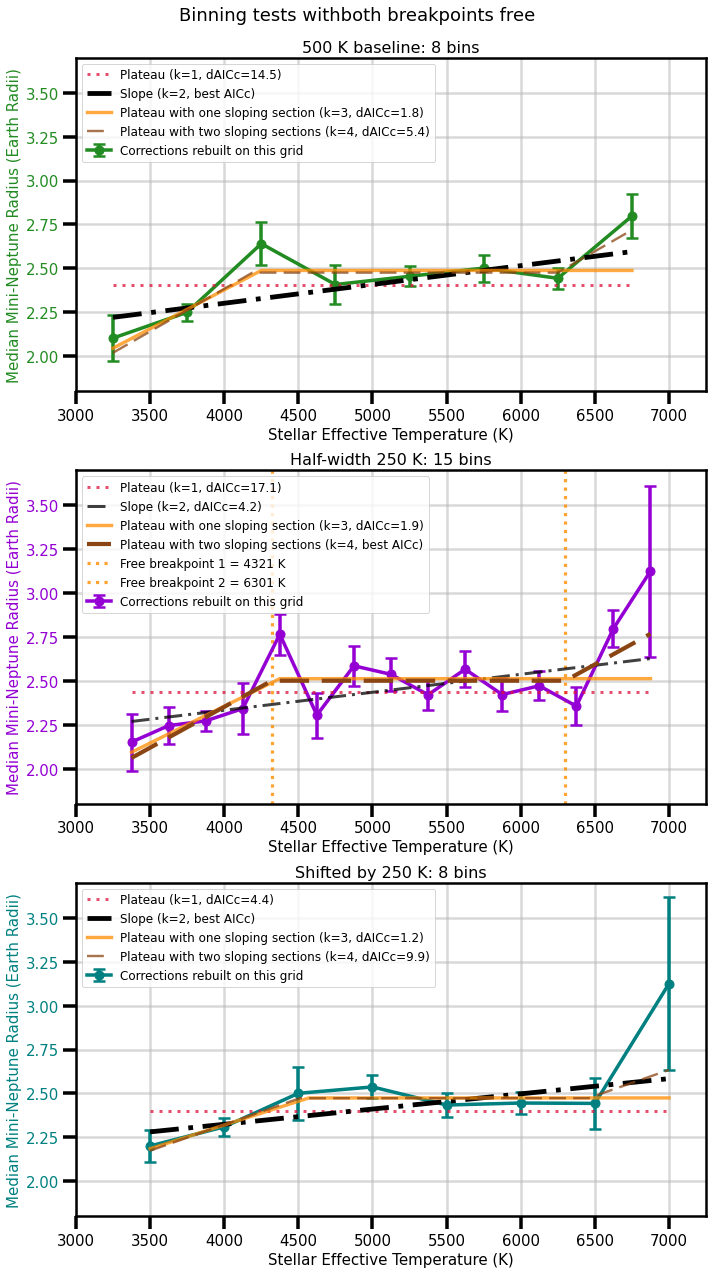

In [3]:
#### MODEL LADDER ON THE NATIVE CORRECTIONS, BOTH BREAKPOINTS FREE ####
# The same four models and the same fitting as the free-breakpoint cell in the main
# notebook, run on both sets of weights so the two can be read side by side. Anything
# that moves here is the correction, not the binning, because the bins are identical.


def plateau(x, c):
    return np.full_like(np.asarray(x, dtype=float), c)


def slope(x, y0, s, x_min):
    return y0 + s * (np.asarray(x, dtype=float) - x_min)


def plateau_M(x, c, x1, s1):
    # Rises with slope s1 below x1, flat at c above it
    x = np.asarray(x, dtype=float)
    return np.where(x < x1, c + s1 * (x - x1), c)


def symmetric(x, c, x1, x2, s):
    # Rise, then flat between x1 and x2, then rise again with the same slope
    x = np.asarray(x, dtype=float)
    return np.select(
        [x < x1, (x >= x1) & (x <= x2), x > x2],
        [c + s * (x - x1), np.full_like(x, c), c + s * (x - x2)],
    )


def fit_ladder(x, y, yerr):
    # Guesses and breakpoint bounds come from this binning's own range. Plateau+M and
    # Symmetric get several starting guesses because the chi2 surface is multi-modal
    # in a breakpoint and a single guess lands in whichever basin it started in.
    n_bins = len(y)
    x_min = x.min()
    x_max = x.max()
    x_span = x_max - x_min
    median_guess = np.median(y)
    slope_guess = (y[-1] - y[0]) / x_span

    def slope_here(x, y0, s):
        return slope(x, y0, s, x_min)

    ladder = {
        'Plateau': {
            'func': plateau,
            'k': 1,
            'guesses': [[median_guess]],
            'bounds': (-np.inf, np.inf),
        },
        'Slope': {
            'func': slope_here,
            'k': 2,
            'guesses': [[y[0], slope_guess]],
            'bounds': (-np.inf, np.inf),
        },
        'Plateau+M': {
            'func': plateau_M,
            'k': 3,
            'guesses': [[median_guess, x_min + f * x_span, slope_guess]
                        for f in (0.2, 0.35, 0.5, 0.65, 0.8)],
            'bounds': ([-np.inf, x_min, -np.inf], [np.inf, x_max, np.inf]),
        },
        'Symmetric': {
            'func': symmetric,
            'k': 4,
            'guesses': [[median_guess, x_min + a * x_span, x_min + b * x_span, slope_guess]
                        for a, b in ((0.2, 0.8), (0.3, 0.7), (0.15, 0.55),
                                     (0.45, 0.85), (0.35, 0.6))],
            'bounds': ([-np.inf, x_min, x_min, -np.inf], [np.inf, x_max, x_max, np.inf]),
        },
    }

    for name, model in ladder.items():
        best_chi2 = np.inf
        best_params = None

        for guess in model['guesses']:
            try:
                params, _ = curve_fit(model['func'], x, y, p0=guess, sigma=yerr,
                                      absolute_sigma=True, bounds=model['bounds'], maxfev=40000)
            except Exception:
                continue
            # Symmetric can fit crossed breakpoints, which are meaningless
            if name == 'Symmetric' and params[1] > params[2]:
                continue
            chi2 = np.sum(((y - model['func'](x, *params)) / yerr) ** 2)
            if chi2 < best_chi2:
                best_chi2 = chi2
                best_params = params

        k = model['k']
        model['chi2'] = best_chi2
        model['params'] = best_params
        model['AICc'] = best_chi2 + 2 * k + 2 * k * (k + 1) / (n_bins - k - 1)

    return ladder


for name, test in tests.items():
    test['ladder_inherited'] = fit_ladder(test['x_inherited'], test['y_inherited'], test['yerr_inherited'])
    test['ladder'] = fit_ladder(test['x'], test['y'], test['yerr'])

    for label, ladder, n_bins in [('inherited', test['ladder_inherited'], len(test['y_inherited'])),
                                  ('native', test['ladder'], len(test['y']))]:
        best_aicc = min(model['AICc'] for model in ladder.values())
        best_name = min(ladder, key=lambda model_name: ladder[model_name]['AICc'])

        print(f"\n{name}, {label} corrections, {n_bins} bins fitted")
        print("=" * 62)
        print(f"{'Model':<12}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}{'AICc':>9}{'dAICc':>9}")
        print("-" * 62)
        for model_name, model in ladder.items():
            dof = n_bins - model['k']
            print(f"{model_name:<12}{model['k']:>3}{model['chi2']:>9.3f}{dof:>5}"
                  f"{model['chi2']/dof:>10.3f}{model['AICc']:>9.3f}{model['AICc']-best_aicc:>9.3f}")
        print(f"  Preferred by AICc: {best_name}")
        print(f"  Plateau+M break:   x1={ladder['Plateau+M']['params'][1]:.0f} K, "
              f"s1={ladder['Plateau+M']['params'][2]*1000:.4f} per 1000 K")
        print(f"  Symmetric breaks:  x1={ladder['Symmetric']['params'][1]:.0f} K, "
              f"x2={ladder['Symmetric']['params'][2]:.0f} K, "
              f"s={ladder['Symmetric']['params'][3]*1000:.4f} per 1000 K")


# Does recalculating the correction change the answer? Read across, not down
print("\n\nDoes the answer survive recalculating the corrections?")
print("=" * 92)
print(f"{'Binning':<18}{'correction':>12}{'preferred':>12}{'M break':>10}"
      f"{'dAICc 2-1':>11}{'dAICc slope':>13}{'dAICc 1-slope':>15}")
print("-" * 92)
for name, test in tests.items():
    for label, ladder in [('inherited', test['ladder_inherited']), ('native', test['ladder'])]:
        best_name = min(ladder, key=lambda model_name: ladder[model_name]['AICc'])
        best_aicc = ladder[best_name]['AICc']
        # Positive means the one-slope model is preferred over the two-slope one
        delta = ladder['Symmetric']['AICc'] - ladder['Plateau+M']['AICc']
        print(f"{name:<18}{label:>12}{best_name:>12}{ladder['Plateau+M']['params'][1]:>10.0f}"
              f"{delta:>11.2f}{ladder['Slope']['AICc']-best_aicc:>13.2f}"
              f"{ladder['Plateau+M']['AICc']-best_aicc:>15.2f}")
print("\ndAICc 2-1 is Symmetric minus Plateau+M: positive favours one sloping section.")
print("dAICc slope and dAICc 1-slope are each model against the best in that row.")


# Create the plot
fig, axes = plt.subplots(3, 1, figsize=(10, 18))

# One y range shared by all three panels so they stay directly comparable, taken from
# the data rather than fixed at 3.5 so that the hottest bin's error bar is not clipped
y_low = 1.8
y_high = 0.0
for test in tests.values():
    y_high = max(y_high, np.max(test['y'] + test['yerr']))
y_high = np.ceil((y_high + 0.05) * 10) / 10

model_labels = {
    'Plateau': 'Plateau',
    'Slope': 'Slope',
    'Plateau+M': 'Plateau with one sloping section',
    'Symmetric': 'Plateau with two sloping sections',
}

model_styles = {
    'Plateau': ('crimson', (0, (1, 2)), 3.0),
    'Slope': ('black', (0, (6, 2, 1, 2)), 3.0),
    'Plateau+M': ('darkorange', '-', 3.4),
    'Symmetric': ('saddlebrown', (0, (7, 3)), 2.4),
}

for ax, (name, test) in zip(axes, tests.items()):
    ladder = test['ladder']
    best_name = min(ladder, key=lambda model_name: ladder[model_name]['AICc'])
    best_aicc = ladder[best_name]['AICc']

    ax.grid(True, which='major', linewidth=2.5, alpha=0.5, color='0.7')
    ax.set_axisbelow(True)

    ax.errorbar(test['x'], test['y'], yerr=test['yerr'], color=test['color'],
                label='Corrections rebuilt on this grid', marker='o', linestyle='-',
                markersize=9, linewidth=3.5, capsize=6, capthick=2.5, zorder=4)

    x_line = np.linspace(test['x'].min(), test['x'].max(), 400)
    for model_name, (color, linestyle, linewidth) in model_styles.items():
        model = ladder[model_name]
        is_best = model_name == best_name
        if is_best:
            label = f"{model_labels[model_name]} (k={model['k']}, best AICc)"
        else:
            label = (f"{model_labels[model_name]} (k={model['k']}, "
                     f"dAICc={model['AICc']-best_aicc:.1f})")
        ax.plot(x_line, model['func'](x_line, *model['params']), color=color,
                linestyle=linestyle, linewidth=linewidth + 1.8 if is_best else linewidth,
                alpha=1.0 if is_best else 0.75, zorder=5, label=label)

    if best_name == 'Symmetric':
        breaks = ladder['Symmetric']['params'][1:3]
    elif best_name == 'Plateau+M':
        breaks = ladder['Plateau+M']['params'][1:2]
    else:
        breaks = []
    break_labels = ['Free breakpoint 1', 'Free breakpoint 2']
    for i in range(len(breaks)):
        ax.axvline(breaks[i], color='darkorange', linestyle=':', linewidth=3.2, alpha=0.8,
                   zorder=1, label=f"{break_labels[i]} = {breaks[i]:.0f} K")

    ax.set_xlabel('Stellar Effective Temperature (K)', size=15)
    ax.set_ylabel('Median Mini-Neptune Radius (Earth Radii)', color=test['color'], size=15)
    ax.tick_params(axis='y', labelcolor=test['color'])
    ax.set_xlim(3000, 7250)
    ax.set_ylim(y_low, y_high)

    ax.set_title(f"{name}: {len(test['y'])} bins", size=16)
    ax.legend(loc='upper left', fontsize=12)
    ax.tick_params(axis='both', which='major', width=3.5, length=13, labelsize=15)
    ax.tick_params(axis='both', which='minor', width=2.5, length=8, labelsize=15)
    for spine in ax.spines.values():
        spine.set_linewidth(2.5)

fig.suptitle('Binning tests withboth breakpoints free', size=18)
fig.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()

fig.savefig('statistical_analysis_teff_native_corrections.png', dpi=300, bbox_inches='tight')

Pin 1.10 Msun = 6014 K, swept 1.03-1.17 Msun = 5860-6154 K

500 K baseline, inherited corrections, 8 bins, x2 pinned at 6014 K
Model               k     chi2  dof  red.chi2     AICc    dAICc
------------------------------------------------------------------
Plateau             1   31.351    7     4.479   34.018   16.100
Slope               2   13.136    6     2.189   19.536    1.618
Plateau+M           3    9.341    5     1.868   21.341    3.423
Symmetric pinned    3    5.918    5     1.184   17.918    0.000
Symmetric free      4    3.600    4     0.900   24.933    7.015
  Pinned fit: c=2.445, x1=4250 K, s=0.3623 per 1000 K

500 K baseline, native corrections, 8 bins, x2 pinned at 6014 K
Model               k     chi2  dof  red.chi2     AICc    dAICc
------------------------------------------------------------------
Plateau             1   31.351    7     4.479   34.018   16.100
Slope               2   13.136    6     2.189   19.536    1.618
Plateau+M           3    9.341    5     1.86

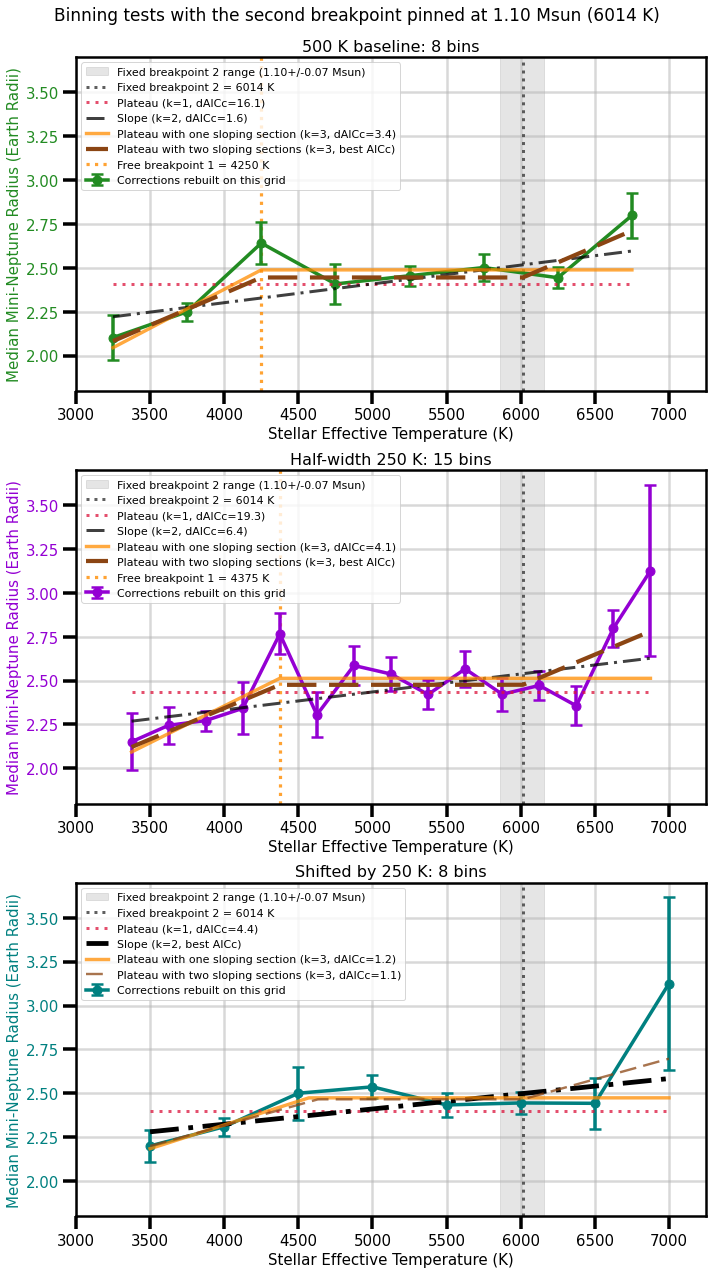

In [4]:
#### THE SAME COMPARISON WITH THE SECOND BREAKPOINT PINNED AT 1.1 MSUN ####
# Mirrors the pinned cell at the end of the main notebook. Holding the hot breakpoint
# drops the two-slope model from k=4 to k=3, the same cost as one sloping section, so
# the two can be compared at equal price. The question here is whether recalculating
# the correction changes which of them wins.
#
# The pin is 1.1 Msun on the Mamajek (2022) dwarf sequence, the same value and the
# same interpolation used in the main notebook.

mamajek_mass = [1.00, 1.03, 1.06, 1.08, 1.13, 1.18, 1.21]
mamajek_teff = [5770, 5860, 5930, 5990, 6050, 6180, 6280]


def teff_for_mass(mass):
    # Linear interpolation onto the dwarf sequence, as used for the earlier pin
    return float(np.interp(mass, mamajek_mass, mamajek_teff))


pin_mass = 1.10
pin_spread = 0.07
pin_masses = np.round(np.arange(pin_mass - pin_spread, pin_mass + pin_spread + 0.001, 0.01), 2)

teff_pin = teff_for_mass(pin_mass)

print(f"Pin {pin_mass:.2f} Msun = {teff_pin:.0f} K, swept "
      f"{pin_mass - pin_spread:.2f}-{pin_mass + pin_spread:.2f} Msun = "
      f"{teff_for_mass(pin_mass - pin_spread):.0f}-{teff_for_mass(pin_mass + pin_spread):.0f} K")


def make_symmetric_pinned(x2_fixed):
    # Symmetric with the upper break held at x2_fixed, so only c, x1 and s are fitted
    def model(x, c, x1, s):
        x = np.asarray(x, dtype=float)
        return np.select(
            [x < x1, (x >= x1) & (x <= x2_fixed), x > x2_fixed],
            [c + s * (x - x1), np.full_like(x, c), c + s * (x - x2_fixed)],
        )
    return model


def fit_symmetric_pinned(x, y, yerr, x2_fixed):
    # x1 is bounded above by the pin so the two breakpoints cannot cross, and it gets
    # several starting guesses because the chi2 surface is multi-modal
    model_func = make_symmetric_pinned(x2_fixed)
    x_min = x.min()
    median_guess = np.median(y)
    slope_guess = (y[-1] - y[0]) / (x.max() - x_min)

    best_chi2 = np.inf
    best_params = None

    for f in (0.2, 0.35, 0.5, 0.65, 0.8):
        guess = [median_guess, x_min + f * (x2_fixed - x_min), slope_guess]
        try:
            params, _ = curve_fit(model_func, x, y, p0=guess, sigma=yerr,
                                  absolute_sigma=True, maxfev=40000,
                                  bounds=([-np.inf, x_min, -np.inf],
                                          [np.inf, x2_fixed, np.inf]))
        except Exception:
            continue
        chi2 = np.sum(((y - model_func(x, *params)) / yerr) ** 2)
        if chi2 < best_chi2:
            best_chi2 = chi2
            best_params = params

    return best_chi2, best_params, model_func


# Plateau, Slope and Plateau+M have no x2 at all, so they are unchanged by the pin and
# are the bar the pinned model has to clear
rivals = ['Plateau', 'Slope', 'Plateau+M']

for name, test in tests.items():
    for label, key, x_key, y_key, err_key in [
            ('inherited', 'ladder_inherited', 'x_inherited', 'y_inherited', 'yerr_inherited'),
            ('native', 'ladder', 'x', 'y', 'yerr')]:
        x = test[x_key]
        y = test[y_key]
        yerr = test[err_key]
        n_bins = len(y)
        ladder = test[key]

        chi2_pin, params_pin, func_pin = fit_symmetric_pinned(x, y, yerr, teff_pin)
        k_pin = 3
        aicc_pin = chi2_pin + 2 * k_pin + 2 * k_pin * (k_pin + 1) / (n_bins - k_pin - 1)
        test[f'pin_chi2_{label}'] = chi2_pin
        test[f'pin_params_{label}'] = params_pin
        test[f'pin_func_{label}'] = func_pin
        test[f'pin_AICc_{label}'] = aicc_pin

        entries = []
        for rival in rivals:
            entries.append((rival, ladder[rival]['k'], ladder[rival]['chi2'], ladder[rival]['AICc']))
        entries.append(('Symmetric pinned', k_pin, chi2_pin, aicc_pin))
        entries.append(('Symmetric free', 4, ladder['Symmetric']['chi2'], ladder['Symmetric']['AICc']))
        best_aicc = min(entry[3] for entry in entries)

        print(f"\n{name}, {label} corrections, {n_bins} bins, x2 pinned at {teff_pin:.0f} K")
        print("=" * 66)
        print(f"{'Model':<18}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}{'AICc':>9}{'dAICc':>9}")
        print("-" * 66)
        for model_name, k, chi2, aicc in entries:
            dof = n_bins - k
            print(f"{model_name:<18}{k:>3}{chi2:>9.3f}{dof:>5}{chi2/dof:>10.3f}"
                  f"{aicc:>9.3f}{aicc-best_aicc:>9.3f}")
        print(f"  Pinned fit: c={params_pin[0]:.3f}, x1={params_pin[1]:.0f} K, "
              f"s={params_pin[2]*1000:.4f} per 1000 K")


# Sweep the pin so the answer cannot rest on a single by-eye number
print("\n\nDoes the pinned model still win when the corrections are rebuilt?")
print("=" * 94)
print(f"{'Binning':<18}{'correction':>12}{'rival':>12}{'rival AICc':>12}"
      f"{'pinned best':>13}{'pinned worst':>14}{'wins at':>11}")
print("-" * 94)
for name, test in tests.items():
    for label, key, x_key, y_key, err_key in [
            ('inherited', 'ladder_inherited', 'x_inherited', 'y_inherited', 'yerr_inherited'),
            ('native', 'ladder', 'x', 'y', 'yerr')]:
        x, y, yerr = test[x_key], test[y_key], test[err_key]
        n_bins = len(y)
        ladder = test[key]

        rival_name = min(rivals, key=lambda r: ladder[r]['AICc'])
        rival_aicc = ladder[rival_name]['AICc']

        swept = []
        for mass in pin_masses:
            chi2_sweep, _, _ = fit_symmetric_pinned(x, y, yerr, teff_for_mass(mass))
            swept.append(chi2_sweep + 2 * 3 + 2 * 3 * 4 / (n_bins - 4))
        swept = np.array(swept)
        wins = int((swept < rival_aicc).sum())

        print(f"{name:<18}{label:>12}{rival_name:>12}{rival_aicc:>12.3f}"
              f"{swept.min():>13.3f}{swept.max():>14.3f}{wins:>8}/{len(pin_masses)}")
print("\nPinned best/worst are the AICc of the pinned model over the swept range.")
print("'wins at' counts the pins where it beats the best model that has no x2.")


# Create the plot
fig, axes = plt.subplots(3, 1, figsize=(10, 18))

for ax, (name, test) in zip(axes, tests.items()):
    ladder = test['ladder']
    entries = {rival: ladder[rival]['AICc'] for rival in rivals}
    entries['Symmetric pinned'] = test['pin_AICc_native']
    best_name = min(entries, key=entries.get)
    best_aicc = entries[best_name]

    ax.grid(True, which='major', linewidth=2.5, alpha=0.5, color='0.7')
    ax.set_axisbelow(True)

    ax.axvspan(teff_for_mass(pin_mass - pin_spread), teff_for_mass(pin_mass + pin_spread),
               color='0.6', alpha=0.25, zorder=0,
               label=f'Fixed breakpoint 2 range ({pin_mass:.2f}+/-{pin_spread:.2f} Msun)')
    ax.axvline(teff_pin, color='0.3', linestyle=':', linewidth=3.0, alpha=0.9, zorder=1,
               label=f'Fixed breakpoint 2 = {teff_pin:.0f} K')

    ax.errorbar(test['x'], test['y'], yerr=test['yerr'], color=test['color'],
                label='Corrections rebuilt on this grid', marker='o', linestyle='-',
                markersize=9, linewidth=3.5, capsize=6, capthick=2.5, zorder=4)

    x_line = np.linspace(test['x'].min(), test['x'].max(), 400)
    for model_name in rivals:
        color, linestyle, linewidth = model_styles[model_name]
        model = ladder[model_name]
        is_best = model_name == best_name
        if is_best:
            label = f"{model_labels[model_name]} (k={model['k']}, best AICc)"
        else:
            label = (f"{model_labels[model_name]} (k={model['k']}, "
                     f"dAICc={model['AICc']-best_aicc:.1f})")
        ax.plot(x_line, model['func'](x_line, *model['params']), color=color,
                linestyle=linestyle, linewidth=linewidth + 1.8 if is_best else linewidth,
                alpha=1.0 if is_best else 0.75, zorder=5, label=label)

    is_best = best_name == 'Symmetric pinned'
    if is_best:
        label = 'Plateau with two sloping sections (k=3, best AICc)'
    else:
        label = ('Plateau with two sloping sections (k=3, '
                 f"dAICc={test['pin_AICc_native']-best_aicc:.1f})")
    ax.plot(x_line, test['pin_func_native'](x_line, *test['pin_params_native']),
            color='saddlebrown', linestyle=(0, (7, 3)),
            linewidth=4.2 if is_best else 2.4, alpha=1.0 if is_best else 0.75,
            zorder=5, label=label)

    # The cool-end breakpoint is still fitted even when the hot one is held
    if best_name == 'Symmetric pinned':
        free_break = test['pin_params_native'][1]
    elif best_name == 'Plateau+M':
        free_break = ladder['Plateau+M']['params'][1]
    else:
        free_break = None
    if free_break is not None:
        ax.axvline(free_break, color='darkorange', linestyle=':', linewidth=3.2, alpha=0.8,
                   zorder=1, label=f'Free breakpoint 1 = {free_break:.0f} K')

    ax.set_xlabel('Stellar Effective Temperature (K)', size=15)
    ax.set_ylabel('Median Mini-Neptune Radius (Earth Radii)', color=test['color'], size=15)
    ax.tick_params(axis='y', labelcolor=test['color'])
    ax.set_xlim(3000, 7250)
    ax.set_ylim(y_low, y_high)

    ax.set_title(f"{name}: {len(test['y'])} bins", size=16)
    ax.legend(loc='upper left', fontsize=11)
    ax.tick_params(axis='both', which='major', width=3.5, length=13, labelsize=15)
    ax.tick_params(axis='both', which='minor', width=2.5, length=8, labelsize=15)
    for spine in ax.spines.values():
        spine.set_linewidth(2.5)

fig.suptitle('Binning tests with the second breakpoint pinned at 1.10 Msun (6014 K)', size=17)
fig.tight_layout(rect=[0, 0, 1, 0.985])
plt.show()

fig.savefig('statistical_analysis_teff_native_corrections_pinned.png', dpi=300, bbox_inches='tight')

Native corrections, 250 K slices shifted by 125 K
  floored 31 zero-detection cells to 1/trials (trials [1, 2, 3, 4, 10, 11, 12, 18])
  completeness match: 672/673 (99.9%), 1 uncorrected

Shifted half-width 125 K: 16 bins
--------------------------------------------------------------------------------------
  Teff (K)         N            inherited               native     shift
  3125-3375       13         2.05 +/-0.131         2.05 +/-0.138    +0.000
  3375-3625       38         2.17 +/-0.148         2.20 +/-0.147    +0.030
  3625-3875       39         2.25 +/-0.119         2.12 +/-0.120    -0.125
  3875-4125       43         2.30 +/-0.059         2.31 +/-0.062    +0.009
  4125-4375       33         2.69 +/-0.152         2.69 +/-0.131    +0.000
  4375-4625       32         2.51 +/-0.180         2.49 +/-0.176    -0.017
  4625-4875       48         2.56 +/-0.137         2.53 +/-0.162    -0.037
  4875-5125       44         2.45 +/-0.128         2.43 +/-0.168    -0.021
  5125-5375       

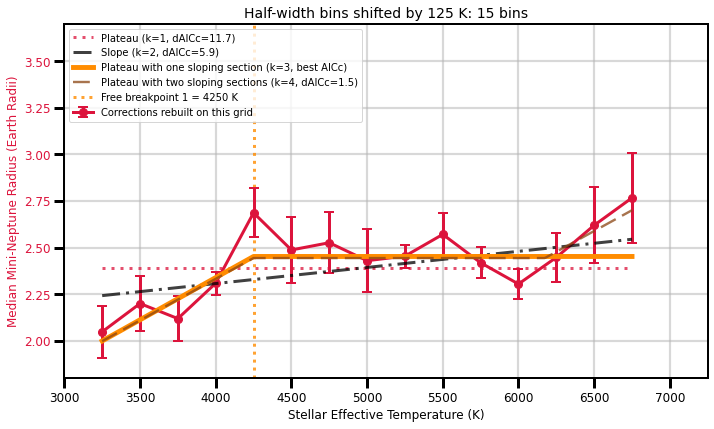

In [5]:
#### FOURTH TEST: HALF-WIDTH BINS SHIFTED BY HALF A BIN ####
# The three tests above move the grid in only two ways: halve the bins, or shift the
# 500 K bins by half of one. This adds the remaining combination -- 250 K bins shifted
# by 125 K -- so the edges sit where none of the other grids put them. If the shape is
# a property of the planets rather than of the binning, this grid should say the same
# thing as the others.
#
# The grid runs 3125-7125 K so that it reaches past the hottest star (6920 K) at both
# ends, and every bin has injections behind it, so nothing is dropped for want of a
# completeness slice. The top bin is dropped for a different reason: it holds a single
# planet, and one planet gives every bootstrap resample the same value, so its error
# bar is rounding noise rather than a measurement.
#
# Completeness comes from native_250K_shifted/, built the same way as the other native
# grids, so this test is run on corrections rebuilt at its own resolution.

bins_half_shifted = list(range(3125, 7126, 250))

print("Native corrections, 250 K slices shifted by 125 K")
planets_half_shifted = build_weights(load_completeness('native_250K_shifted'),
                                     teff_ranges_from(bins_half_shifted))

fourth = {'edges': bins_half_shifted, 'color': 'crimson'}

centers, medians, errors, counts, no_cell = corrected_medians(planets_inherited, fourth['edges'])
good_inherited = usable(medians, errors, counts, no_cell)
fourth['x_inherited'] = centers[good_inherited]
fourth['y_inherited'] = medians[good_inherited]
fourth['yerr_inherited'] = errors[good_inherited]

centers, medians_native, errors_native, counts, no_cell = corrected_medians(planets_half_shifted, fourth['edges'])
good = usable(medians_native, errors_native, counts, no_cell)
fourth['x'] = centers[good]
fourth['y'] = medians_native[good]
fourth['yerr'] = errors_native[good]

print(f"\nShifted half-width 125 K: {len(fourth['edges']) - 1} bins")
print("-" * 86)
print(f"  {'Teff (K)':<14}{'N':>4}{'inherited':>21}{'native':>21}{'shift':>10}")
for i in range(len(centers)):
    warn = f"  *** {no_cell[i]} with no completeness cell ***" if no_cell[i] else ""
    if not good[i]:
        print(f"  {fourth['edges'][i]}-{fourth['edges'][i+1]:<8} {counts[i]:>4}  dropped{warn}")
        continue
    print(f"  {fourth['edges'][i]}-{fourth['edges'][i+1]:<8} {counts[i]:>4}"
          f"{medians[i]:>13.2f} +/-{errors[i]:>5.3f}"
          f"{medians_native[i]:>13.2f} +/-{errors_native[i]:>5.3f}"
          f"{medians_native[i] - medians[i]:>+10.3f}{warn}")

fourth['ladder_inherited'] = fit_ladder(fourth['x_inherited'], fourth['y_inherited'], fourth['yerr_inherited'])
fourth['ladder'] = fit_ladder(fourth['x'], fourth['y'], fourth['yerr'])

for label, key, x_key, y_key, err_key in [
        ('inherited', 'ladder_inherited', 'x_inherited', 'y_inherited', 'yerr_inherited'),
        ('native', 'ladder', 'x', 'y', 'yerr')]:
    x, y, yerr = fourth[x_key], fourth[y_key], fourth[err_key]
    n_bins = len(y)
    ladder = fourth[key]

    chi2_pin, params_pin, func_pin = fit_symmetric_pinned(x, y, yerr, teff_pin)
    aicc_pin = chi2_pin + 2 * 3 + 2 * 3 * 4 / (n_bins - 4)
    fourth[f'pin_params_{label}'] = params_pin
    fourth[f'pin_func_{label}'] = func_pin
    fourth[f'pin_AICc_{label}'] = aicc_pin

    entries = []
    for rival in rivals:
        entries.append((rival, ladder[rival]['k'], ladder[rival]['chi2'], ladder[rival]['AICc']))
    entries.append(('Symmetric pinned', 3, chi2_pin, aicc_pin))
    entries.append(('Symmetric free', 4, ladder['Symmetric']['chi2'], ladder['Symmetric']['AICc']))
    best_aicc = min(entry[3] for entry in entries)

    print(f"\nShifted half-width 125 K, {label} corrections, {n_bins} bins fitted")
    print("=" * 66)
    print(f"{'Model':<18}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}{'AICc':>9}{'dAICc':>9}")
    print("-" * 66)
    for model_name, k, chi2, aicc in entries:
        dof = n_bins - k
        print(f"{model_name:<18}{k:>3}{chi2:>9.3f}{dof:>5}{chi2/dof:>10.3f}"
              f"{aicc:>9.3f}{aicc-best_aicc:>9.3f}")
    free_best = min(ladder, key=lambda m: ladder[m]['AICc'])
    print(f"  Preferred with both breaks free: {free_best}")
    print(f"  Plateau+M break:   x1={ladder['Plateau+M']['params'][1]:.0f} K, "
          f"s1={ladder['Plateau+M']['params'][2]*1000:.4f} per 1000 K")
    print(f"  Symmetric breaks:  x1={ladder['Symmetric']['params'][1]:.0f} K, "
          f"x2={ladder['Symmetric']['params'][2]:.0f} K")
    print(f"  Pinned fit:        x1={params_pin[1]:.0f} K, "
          f"s={params_pin[2]*1000:.4f} per 1000 K")


# Read this row against the three printed by the cells above
print("\n\nThe fourth grid against the other three")
print("=" * 92)
print(f"{'Binning':<26}{'correction':>12}{'preferred':>12}{'M break':>10}"
      f"{'dAICc 2-1':>11}{'dAICc slope':>13}{'dAICc 1-slope':>15}")
print("-" * 92)
all_tests = dict(tests)
all_tests['Shifted half-width 125 K'] = fourth
for name, test in all_tests.items():
    for label, key in [('inherited', 'ladder_inherited'), ('native', 'ladder')]:
        ladder = test[key]
        best_name = min(ladder, key=lambda m: ladder[m]['AICc'])
        best_aicc = ladder[best_name]['AICc']
        delta = ladder['Symmetric']['AICc'] - ladder['Plateau+M']['AICc']
        print(f"{name:<26}{label:>12}{best_name:>12}{ladder['Plateau+M']['params'][1]:>10.0f}"
              f"{delta:>11.2f}{ladder['Slope']['AICc']-best_aicc:>13.2f}"
              f"{ladder['Plateau+M']['AICc']-best_aicc:>15.2f}")
print("\ndAICc 2-1 is Symmetric minus Plateau+M: positive favours one sloping section.")
print("dAICc slope and dAICc 1-slope are each model against the best in that row.")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))

ladder = fourth['ladder']
best_name = min(ladder, key=lambda m: ladder[m]['AICc'])
best_aicc = ladder[best_name]['AICc']

ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

ax.errorbar(fourth['x'], fourth['y'], yerr=fourth['yerr'], color=fourth['color'],
            label='Corrections rebuilt on this grid', marker='o', linestyle='-',
            markersize=8, linewidth=3, capsize=5, capthick=2, zorder=4)

x_line = np.linspace(fourth['x'].min(), fourth['x'].max(), 400)
for model_name, (color, linestyle, linewidth) in model_styles.items():
    model = ladder[model_name]
    is_best = model_name == best_name
    if is_best:
        label = f"{model_labels[model_name]} (k={model['k']}, best AICc)"
    else:
        label = (f"{model_labels[model_name]} (k={model['k']}, "
                 f"dAICc={model['AICc']-best_aicc:.1f})")
    ax.plot(x_line, model['func'](x_line, *model['params']), color=color,
            linestyle=linestyle, linewidth=linewidth + 1.5 if is_best else linewidth,
            alpha=1.0 if is_best else 0.75, zorder=5, label=label)

if best_name == 'Symmetric':
    breaks = ladder['Symmetric']['params'][1:3]
elif best_name == 'Plateau+M':
    breaks = ladder['Plateau+M']['params'][1:2]
else:
    breaks = []
break_labels = ['Free breakpoint 1', 'Free breakpoint 2']
for i in range(len(breaks)):
    ax.axvline(breaks[i], color='darkorange', linestyle=':', linewidth=3, alpha=0.8,
               zorder=1, label=f"{break_labels[i]} = {breaks[i]:.0f} K")

ax.set_xlabel('Stellar Effective Temperature (K)', size=12)
ax.set_ylabel('Median Mini-Neptune Radius (Earth Radii)', color=fourth['color'], size=12)
ax.tick_params(axis='y', labelcolor=fourth['color'])
ax.set_xlim(3000, 7250)
ax.set_ylim(y_low, y_high)
ax.set_title(f"Half-width bins shifted by 125 K: {len(fourth['y'])} bins", size=14)
ax.legend(loc='upper left', fontsize=10)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)

fig.tight_layout()
plt.show()

fig.savefig('statistical_analysis_teff_native_corrections_halfshift.png', dpi=300, bbox_inches='tight')

Offset 0 K, 16 bins
  floored 11 zero-detection cells to 1/trials (trials [3, 4, 5, 9, 10, 11])
  completeness match: 669/673 (99.4%), 4 uncorrected
Offset 25 K, 16 bins
  floored 23 zero-detection cells to 1/trials (trials [1, 2, 3, 4, 6, 9, 13])
  completeness match: 668/673 (99.3%), 5 uncorrected
Offset 50 K, 16 bins
  floored 19 zero-detection cells to 1/trials (trials [1, 2, 3, 4, 6, 8, 9, 12, 13])
  completeness match: 669/673 (99.4%), 4 uncorrected
Offset 75 K, 16 bins
  floored 25 zero-detection cells to 1/trials (trials [1, 2, 3, 4, 5, 7, 8, 10, 11, 14, 15])
  completeness match: 671/673 (99.7%), 2 uncorrected
Offset 100 K, 16 bins
  floored 28 zero-detection cells to 1/trials (trials [1, 2, 3, 4, 9, 10, 11, 12, 16])
  completeness match: 672/673 (99.9%), 1 uncorrected
Offset 125 K, 16 bins
  floored 31 zero-detection cells to 1/trials (trials [1, 2, 3, 4, 10, 11, 12, 18])
  completeness match: 672/673 (99.9%), 1 uncorrected
Offset 150 K, 16 bins
  floored 6 zero-detection cel

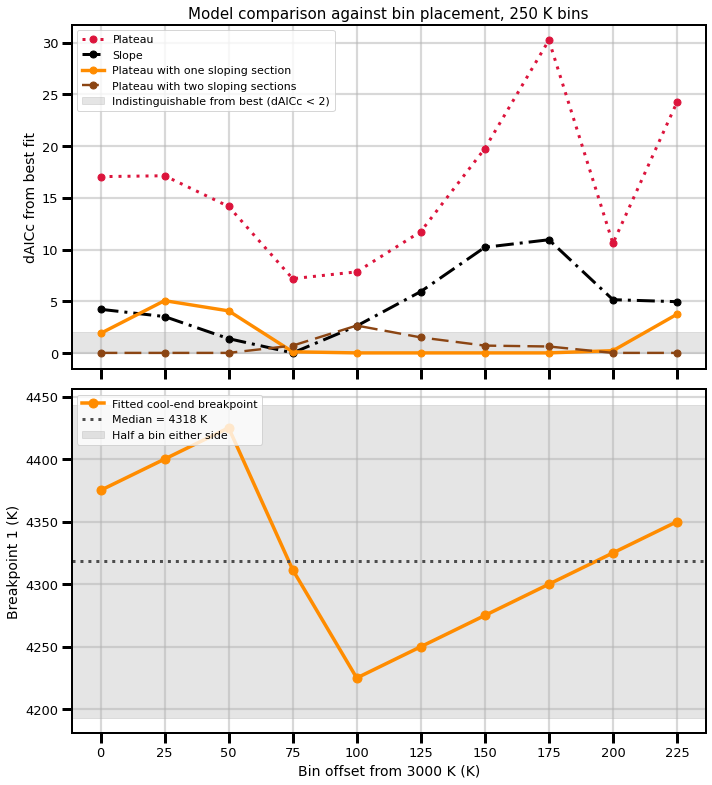

In [6]:
#### FIFTH TEST: SWEEPING THE BIN OFFSET ####
# The four grids above sample bin placement at four points. The referee's question is
# about sensitivity to placement in general, so this sweeps it properly: bins of a fixed
# width slid across a full bin period. Two of the 250 K offsets reproduce tests already
# done -- offset 0 is the half-width grid and offset 125 is the shifted half-width grid
# -- which is a useful check that nothing here contradicts them.
#
# Each offset gets its own completeness grid under native_offsets*/, so every fit uses
# corrections rebuilt at its own edges rather than inherited ones.
#
# What matters is not any single row but whether the answer moves: if the cool-end
# slope is a property of the planets, it should survive every placement, and the fitted
# breakpoint should wander by about a bin width rather than jump around.
#
# The same machinery is reused for the 500 K and 100 K sweeps in the cells below.

max_teff = 6920  # the hottest star in the sample


def sweep_edges(width, offset):
    # Bins of `width` starting at 3000 + offset, extended until the top edge clears the
    # hottest star, so no trailing empty bin is ever generated
    edges = [3000 + offset]
    while edges[-1] <= max_teff:
        edges.append(edges[-1] + width)
    return edges


def offset_sweep(width, offsets, directory):
    # Refit the whole ladder at each placement, on corrections rebuilt for that placement
    sweep = []
    for offset in offsets:
        edges = sweep_edges(width, offset)
        print(f"Offset {offset} K, {len(edges) - 1} bins")
        planets = build_weights(load_completeness(f'{directory}/offset_{offset}'),
                                teff_ranges_from(edges))

        centers, medians, errors, counts, no_cell = corrected_medians(planets, edges)
        good = usable(medians, errors, counts, no_cell)
        ladder = fit_ladder(centers[good], medians[good], errors[good])

        best_name = min(ladder, key=lambda m: ladder[m]['AICc'])
        best_aicc = ladder[best_name]['AICc']
        sweep.append({
            'offset': offset,
            'n_bins': int(good.sum()),
            'n_dropped': int((~good).sum()),
            'best': best_name,
            'ladder': ladder,
            'x1': ladder['Plateau+M']['params'][1],
            'slope_M': ladder['Plateau+M']['params'][2] * 1000,
            'delta': {name: ladder[name]['AICc'] - best_aicc for name in ladder},
        })
    return sweep


def report_sweep(sweep, width):
    print(f"\n\nDoes the answer survive sliding the {width} K grid?")
    print("=" * 96)
    print(f"{'offset':>7}{'bins':>6}{'dropped':>9}{'preferred':>12}"
          f"{'dAICc plateau':>15}{'dAICc slope':>13}{'dAICc 1-sec':>13}{'dAICc 2-sec':>13}{'x1 (K)':>9}")
    print("-" * 96)
    for row in sweep:
        print(f"{row['offset']:>7}{row['n_bins']:>6}{row['n_dropped']:>9}{row['best']:>12}"
              f"{row['delta']['Plateau']:>15.2f}{row['delta']['Slope']:>13.2f}"
              f"{row['delta']['Plateau+M']:>13.2f}{row['delta']['Symmetric']:>13.2f}{row['x1']:>9.0f}")

    print(f"\nAcross the {len(sweep)} placements")
    print("-" * 64)
    winners = {}
    for row in sweep:
        winners[row['best']] = winners.get(row['best'], 0) + 1
    for name, count in sorted(winners.items(), key=lambda kv: -kv[1]):
        print(f"  preferred {name:<12} at {count}/{len(sweep)} offsets")

    breaks = np.array([row['x1'] for row in sweep])
    slopes = np.array([row['slope_M'] for row in sweep])
    print(f"  Cool-end breakpoint: {breaks.min():.0f}-{breaks.max():.0f} K, "
          f"median {np.median(breaks):.0f} K, spread {breaks.max() - breaks.min():.0f} K "
          f"against a {width} K bin")
    print(f"  Cool-end slope:      {slopes.min():.3f}-{slopes.max():.3f} R_Earth per 1000 K")

    print("\n  Within 2 AICc of the best fit at each offset:")
    for name in ('Plateau', 'Slope', 'Plateau+M', 'Symmetric'):
        count = sum(1 for row in sweep if row['delta'][name] <= 2.0)
        print(f"    {model_labels[name]:<34} {count:>2}/{len(sweep)} offsets")
    return breaks


def plot_sweep(sweep, width, filename):
    offsets = [row['offset'] for row in sweep]
    breaks = np.array([row['x1'] for row in sweep])

    fig, axes = plt.subplots(2, 1, figsize=(10, 11), sharex=True)

    # Top: how far each model sits from the best fit at every placement
    for model_name, (color, linestyle, linewidth) in model_styles.items():
        axes[0].plot(offsets, [row['delta'][model_name] for row in sweep], color=color,
                     linestyle=linestyle, linewidth=linewidth, marker='o', markersize=7,
                     label=model_labels[model_name])
    axes[0].axhspan(0, 2, color='0.6', alpha=0.25, zorder=0,
                    label='Indistinguishable from best (dAICc < 2)')
    axes[0].set_ylabel('dAICc from best fit', size=14)
    axes[0].set_title(f'Model comparison against bin placement, {width} K bins', size=15)
    axes[0].legend(loc='upper left', fontsize=11)

    # Bottom: the cool-end breakpoint, with half a bin drawn either side for scale
    axes[1].plot(offsets, breaks, color='darkorange', linewidth=3.5, marker='o', markersize=9,
                 label='Fitted cool-end breakpoint')
    axes[1].axhline(np.median(breaks), color='0.3', linestyle=':', linewidth=3,
                    label=f'Median = {np.median(breaks):.0f} K')
    axes[1].axhspan(np.median(breaks) - width / 2, np.median(breaks) + width / 2,
                    color='0.6', alpha=0.25, zorder=0, label='Half a bin either side')
    axes[1].set_ylabel('Breakpoint 1 (K)', size=14)
    axes[1].set_xlabel('Bin offset from 3000 K (K)', size=14)
    axes[1].legend(loc='upper left', fontsize=11)

    for ax in axes:
        ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
        ax.set_axisbelow(True)
        ax.set_xticks(offsets)
        ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=13)
        for spine in ax.spines.values():
            spine.set_linewidth(2)

    fig.tight_layout()
    plt.show()
    fig.savefig(filename, dpi=300, bbox_inches='tight')


offsets_250 = list(range(0, 250, 25))
sweep_250 = offset_sweep(250, offsets_250, 'native_offsets')
breaks_250 = report_sweep(sweep_250, 250)
plot_sweep(sweep_250, 250, 'statistical_analysis_teff_offset_sweep.png')

Equal-count edges: [3000, 3654, 4007, 4402, 4803, 5059, 5292, 5518, 5654, 5809, 6016, 6213, 7000]

Native corrections, equal-count slices
  completeness match: 672/673 (99.9%), 1 uncorrected

Equal-count bins: 12 bins
--------------------------------------------------------------------------
  Teff (K)        width    N             median
  3000-3654        654   56         2.15 +/-0.091
  3654-4007        353   56         2.25 +/-0.050
  4007-4402        395   56         2.59 +/-0.154
  4402-4803        401   56         2.53 +/-0.129
  4803-5059        256   56         2.48 +/-0.147
  5059-5292        233   56         2.43 +/-0.120
  5292-5518        226   57         2.41 +/-0.093
  5518-5654        136   55         2.66 +/-0.100
  5654-5809        155   56         2.42 +/-0.086  *** 1 with no completeness cell ***
  5809-6016        207   56         2.34 +/-0.107
  6016-6213        197   57         2.45 +/-0.098
  6213-7000        787   56         2.41 +/-0.150

Equal-count, native c

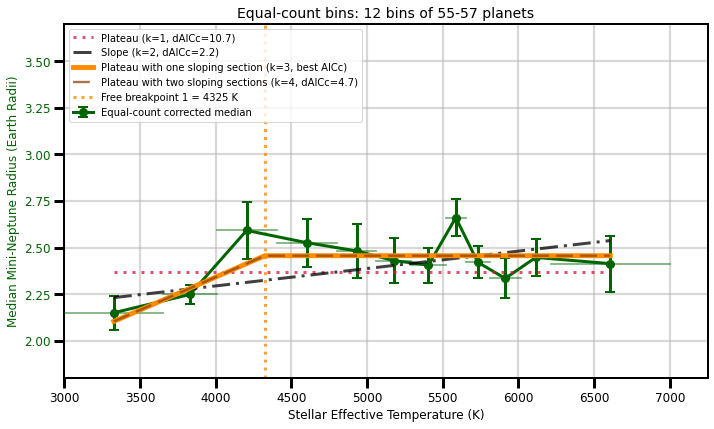

In [7]:
#### SIXTH TEST: EQUAL-COUNT BINS INSTEAD OF EQUAL-WIDTH ####
# Every grid so far divides Teff evenly, which leaves the number of planets per bin
# ranging from 1 to 168. That is what forced bins to be dropped above, and it lets a
# handful of planets at the hot end carry more of the fit than their numbers warrant.
# This bin divides the sample evenly instead: twelve bins of 55-57 planets each.
#
# The trade is real and worth stating rather than hiding. Equal-count bins are narrow
# where planets are common (137 K around 5500-5700 K) and wide where they are not
# (654 K below 3654 K, 787 K above 6213 K), so this grid smooths precisely the two ends
# the paper's claim rests on. It is a test of whether the shape survives uniform
# statistical weight, not a better grid than the others.
#
# The edges come from the planet sample, so they are data-dependent in a way the
# equal-width grids are not. That does not bias the shape, but it does mean this test
# cannot be read as fully independent of the data being fitted.

quantile_bins = 12
sample_teff = np.sort(load_tois()['st_teff'].values)
quantile_edges = np.quantile(sample_teff, np.linspace(0, 1, quantile_bins + 1))
quantile_edges[0], quantile_edges[-1] = 3000, 7000
quantile_edges = [int(round(edge)) for edge in quantile_edges]
for i in range(1, len(quantile_edges)):
    if quantile_edges[i] <= quantile_edges[i - 1]:
        quantile_edges[i] = quantile_edges[i - 1] + 1

print(f"Equal-count edges: {quantile_edges}")

print("\nNative corrections, equal-count slices")
planets_quantile = build_weights(load_completeness('native_quantile'),
                                 teff_ranges_from(quantile_edges))

equal_count = {'edges': quantile_edges, 'color': 'darkgreen'}
centers, medians, errors, counts, no_cell = corrected_medians(planets_quantile, quantile_edges)
good = usable(medians, errors, counts, no_cell)
equal_count['x'] = centers[good]
equal_count['y'] = medians[good]
equal_count['yerr'] = errors[good]

print(f"\nEqual-count bins: {len(quantile_edges) - 1} bins")
print("-" * 74)
print(f"  {'Teff (K)':<14}{'width':>7}{'N':>5}{'median':>19}")
for i in range(len(centers)):
    width = quantile_edges[i + 1] - quantile_edges[i]
    warn = f"  *** {no_cell[i]} with no completeness cell ***" if no_cell[i] else ""
    if not good[i]:
        print(f"  {quantile_edges[i]}-{quantile_edges[i+1]:<8}{width:>7}{counts[i]:>5}  dropped{warn}")
        continue
    print(f"  {quantile_edges[i]}-{quantile_edges[i+1]:<8}{width:>7}{counts[i]:>5}"
          f"{medians[i]:>13.2f} +/-{errors[i]:>5.3f}{warn}")

equal_count['ladder'] = fit_ladder(equal_count['x'], equal_count['y'], equal_count['yerr'])
ladder = equal_count['ladder']
n_bins = len(equal_count['y'])

chi2_pin, params_pin, func_pin = fit_symmetric_pinned(
    equal_count['x'], equal_count['y'], equal_count['yerr'], teff_pin)
aicc_pin = chi2_pin + 2 * 3 + 2 * 3 * 4 / (n_bins - 4)
equal_count['pin_params_native'] = params_pin
equal_count['pin_func_native'] = func_pin
equal_count['pin_AICc_native'] = aicc_pin

entries = []
for rival in rivals:
    entries.append((rival, ladder[rival]['k'], ladder[rival]['chi2'], ladder[rival]['AICc']))
entries.append(('Symmetric pinned', 3, chi2_pin, aicc_pin))
entries.append(('Symmetric free', 4, ladder['Symmetric']['chi2'], ladder['Symmetric']['AICc']))
best_aicc = min(entry[3] for entry in entries)

print(f"\nEqual-count, native corrections, {n_bins} bins fitted")
print("=" * 66)
print(f"{'Model':<18}{'k':>3}{'chi2':>9}{'dof':>5}{'red.chi2':>10}{'AICc':>9}{'dAICc':>9}")
print("-" * 66)
for model_name, k, chi2, aicc in entries:
    dof = n_bins - k
    print(f"{model_name:<18}{k:>3}{chi2:>9.3f}{dof:>5}{chi2/dof:>10.3f}"
          f"{aicc:>9.3f}{aicc-best_aicc:>9.3f}")
free_best = min(ladder, key=lambda m: ladder[m]['AICc'])
print(f"  Preferred with both breaks free: {free_best}")
print(f"  Plateau+M break:   x1={ladder['Plateau+M']['params'][1]:.0f} K, "
      f"s1={ladder['Plateau+M']['params'][2]*1000:.4f} per 1000 K")
print(f"  Symmetric breaks:  x1={ladder['Symmetric']['params'][1]:.0f} K, "
      f"x2={ladder['Symmetric']['params'][2]:.0f} K")
print(f"  Pinned fit:        x1={params_pin[1]:.0f} K, s={params_pin[2]*1000:.4f} per 1000 K")

# Error bars should now be comparable bin to bin, which was the point of the exercise
print(f"\n  Error bars: {equal_count['yerr'].min():.3f}-{equal_count['yerr'].max():.3f} R_Earth "
      f"(ratio {equal_count['yerr'].max()/equal_count['yerr'].min():.1f}), "
      f"against {tests['Half-width 250 K']['yerr'].min():.3f}-"
      f"{tests['Half-width 250 K']['yerr'].max():.3f} "
      f"(ratio {tests['Half-width 250 K']['yerr'].max()/tests['Half-width 250 K']['yerr'].min():.1f}) "
      f"for the 250 K grid")


# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))

best_name = min(ladder, key=lambda m: ladder[m]['AICc'])
best_aicc_free = ladder[best_name]['AICc']

ax.grid(True, which='major', linewidth=2.2, alpha=0.5, color='0.7')
ax.set_axisbelow(True)

# Horizontal bars showing how wide each bin actually is, since they are not uniform
for i in range(len(centers)):
    if not good[i]:
        continue
    ax.plot([quantile_edges[i], quantile_edges[i + 1]], [medians[i], medians[i]],
            color=equal_count['color'], linewidth=1.8, alpha=0.5, zorder=3)

ax.errorbar(equal_count['x'], equal_count['y'], yerr=equal_count['yerr'],
            color=equal_count['color'], label='Equal-count corrected median',
            marker='o', linestyle='-', markersize=8, linewidth=3,
            capsize=5, capthick=2, zorder=4)

x_line = np.linspace(equal_count['x'].min(), equal_count['x'].max(), 400)
for model_name, (color, linestyle, linewidth) in model_styles.items():
    model = ladder[model_name]
    is_best = model_name == best_name
    if is_best:
        label = f"{model_labels[model_name]} (k={model['k']}, best AICc)"
    else:
        label = (f"{model_labels[model_name]} (k={model['k']}, "
                 f"dAICc={model['AICc']-best_aicc_free:.1f})")
    ax.plot(x_line, model['func'](x_line, *model['params']), color=color,
            linestyle=linestyle, linewidth=linewidth + 1.5 if is_best else linewidth,
            alpha=1.0 if is_best else 0.75, zorder=5, label=label)

if best_name == 'Symmetric':
    breaks_here = ladder['Symmetric']['params'][1:3]
elif best_name == 'Plateau+M':
    breaks_here = ladder['Plateau+M']['params'][1:2]
else:
    breaks_here = []
break_labels = ['Free breakpoint 1', 'Free breakpoint 2']
for i in range(len(breaks_here)):
    ax.axvline(breaks_here[i], color='darkorange', linestyle=':', linewidth=3, alpha=0.8,
               zorder=1, label=f"{break_labels[i]} = {breaks_here[i]:.0f} K")

ax.set_xlabel('Stellar Effective Temperature (K)', size=12)
ax.set_ylabel('Median Mini-Neptune Radius (Earth Radii)', color=equal_count['color'], size=12)
ax.tick_params(axis='y', labelcolor=equal_count['color'])
ax.set_xlim(3000, 7250)
ax.set_ylim(y_low, y_high)
ax.set_title(f'Equal-count bins: {n_bins} bins of 55-57 planets', size=14)
ax.legend(loc='upper left', fontsize=10)
ax.tick_params(axis='both', which='major', width=3, length=10, labelsize=12)
for spine in ax.spines.values():
    spine.set_linewidth(2)

fig.tight_layout()
plt.show()

fig.savefig('statistical_analysis_teff_equal_count.png', dpi=300, bbox_inches='tight')

Offset 0 K, 8 bins
  floored 2 zero-detection cells to 1/trials (trials [16, 20])
  completeness match: 672/673 (99.9%), 1 uncorrected
Offset 50 K, 8 bins
  floored 2 zero-detection cells to 1/trials (trials [16, 18])
  completeness match: 672/673 (99.9%), 1 uncorrected
Offset 100 K, 8 bins
  floored 4 zero-detection cells to 1/trials (trials [10, 13, 14, 15])
  completeness match: 672/673 (99.9%), 1 uncorrected
Offset 150 K, 8 bins
  floored 5 zero-detection cells to 1/trials (trials [8, 9, 11, 13])
  completeness match: 671/673 (99.7%), 2 uncorrected
Offset 200 K, 8 bins
  floored 7 zero-detection cells to 1/trials (trials [4, 6, 7, 9, 11, 12])
  completeness match: 670/673 (99.6%), 3 uncorrected
Offset 250 K, 8 bins
  floored 9 zero-detection cells to 1/trials (trials [3, 4, 5, 9, 10])
  completeness match: 669/673 (99.4%), 4 uncorrected
Offset 300 K, 8 bins
  floored 12 zero-detection cells to 1/trials (trials [2, 3, 4, 6, 8, 22])
  completeness match: 664/673 (98.7%), 9 uncorrecte

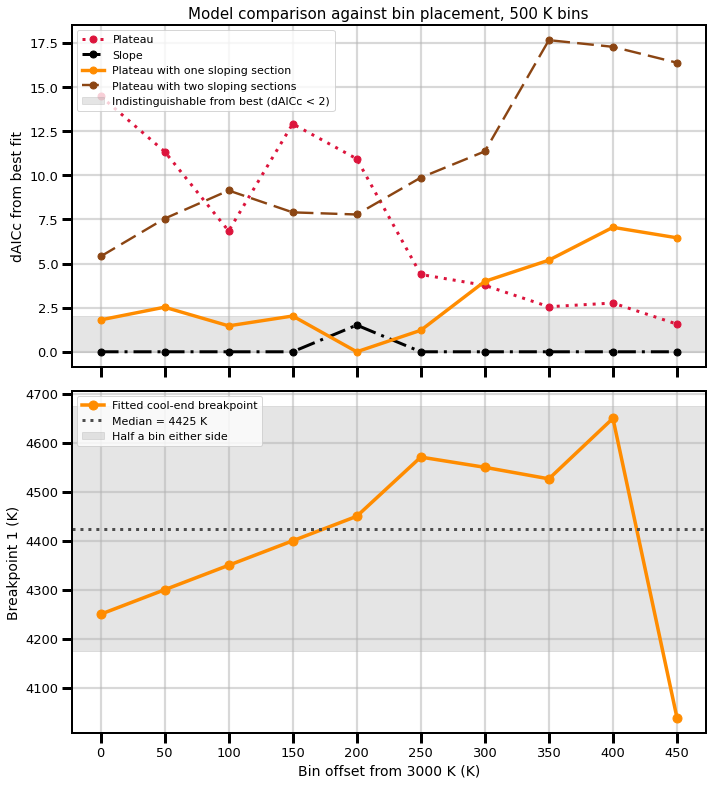

In [8]:
#### SEVENTH TEST: THE SAME SWEEP ON THE 500 K GRID ####
# The sweep above slides 250 K bins. This repeats it at the width the paper actually
# uses, 500 K, slid in 50 K steps across a full bin period. Offset 0 is the baseline
# grid and offset 250 is the shifted grid from the cells above, so those two rows are
# consistency checks rather than new information.
#
# Coarser bins hold more planets each, so the error bars shrink and the fit has more to
# work with per point -- but there are only 8 of them, which is close to the floor for a
# k=4 model, so a single bin moving matters more here than it does at 250 K.

offsets_500 = list(range(0, 500, 50))
sweep_500 = offset_sweep(500, offsets_500, 'native_offsets_500K')
breaks_500 = report_sweep(sweep_500, 500)
plot_sweep(sweep_500, 500, 'statistical_analysis_teff_offset_sweep_500K.png')

Offset 0 K, 40 bins
  floored 74 zero-detection cells to 1/trials (trials [1, 2, 3, 4, 5, 6, 7, 8, 12])
  completeness match: 668/673 (99.3%), 5 uncorrected
Offset 25 K, 39 bins
  floored 43 zero-detection cells to 1/trials (trials [1, 2, 3, 4, 5, 6, 7, 8, 12])
  completeness match: 670/673 (99.6%), 3 uncorrected
Offset 50 K, 39 bins
  floored 50 zero-detection cells to 1/trials (trials [1, 2, 3, 4, 5, 6, 7, 8, 19])
  completeness match: 669/673 (99.4%), 4 uncorrected
Offset 75 K, 39 bins
  floored 65 zero-detection cells to 1/trials (trials [1, 2, 3, 4, 5, 6, 7, 8, 9, 10])
  completeness match: 667/673 (99.1%), 6 uncorrected


Does the answer survive sliding the 100 K grid?
 offset  bins  dropped   preferred  dAICc plateau  dAICc slope  dAICc 1-sec  dAICc 2-sec   x1 (K)
------------------------------------------------------------------------------------------------
      0    37        3   Symmetric          33.89        14.03         1.65         0.00     4317
     25    36        3 

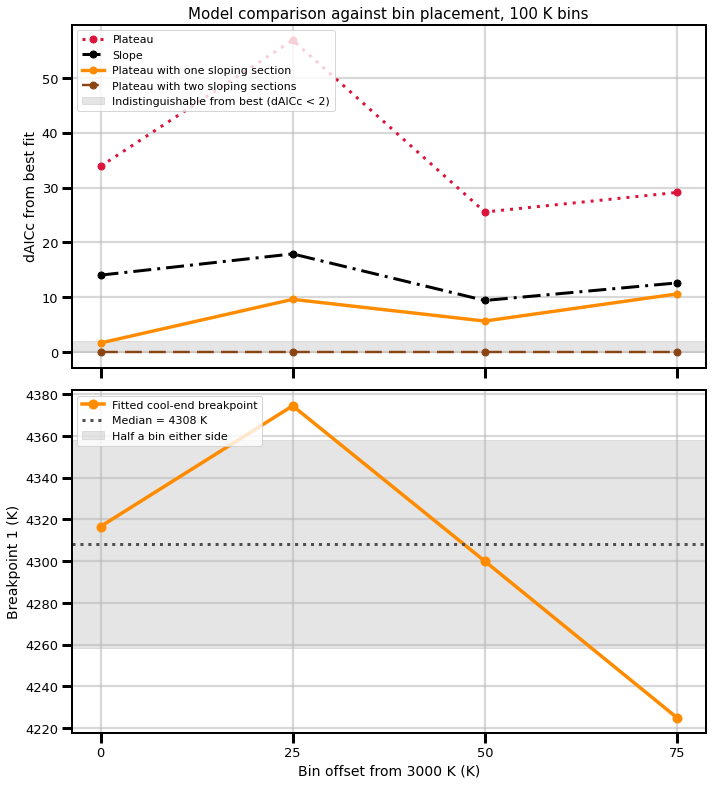

In [9]:
#### EIGHTH TEST: THE SAME SWEEP ON A 100 K GRID ####
# The finest grid the sample supports. Forty bins holding a median of about sixteen
# planets each, slid in 25 K steps over a full bin period. Two bins at the cool end hold
# fewer than two planets and are dropped, as the counts below show.
#
# This is the noisiest test of the set and should be read as a limit rather than as a
# measurement. Each 100 K completeness slice is built from as few as a handful of
# injected stars, so its 42 cells carry roughly 10-50 trials each, and a cell with no
# detections has to be floored at 1/trials. The detection rates behind these weights are
# therefore much rougher than at 250 K or 500 K.

offsets_100 = list(range(0, 100, 25))
sweep_100 = offset_sweep(100, offsets_100, 'native_offsets_100K')
breaks_100 = report_sweep(sweep_100, 100)
plot_sweep(sweep_100, 100, 'statistical_analysis_teff_offset_sweep_100K.png')


# The three widths side by side: does the answer depend on how finely we bin at all?
print("\n\nAll three sweeps together")
print("=" * 78)
print(f"{'width':>7}{'offsets':>9}{'flat rejected':>15}{'1-sec within 2':>16}"
      f"{'2-sec within 2':>16}{'x1 spread':>13}")
print("-" * 78)
for width, sweep in ((500, sweep_500), (250, sweep_250), (100, sweep_100)):
    flat = sum(1 for row in sweep if row['delta']['Plateau'] > 2.0)
    one = sum(1 for row in sweep if row['delta']['Plateau+M'] <= 2.0)
    two = sum(1 for row in sweep if row['delta']['Symmetric'] <= 2.0)
    breaks = np.array([row['x1'] for row in sweep])
    print(f"{width:>7}{len(sweep):>9}{flat:>9}/{len(sweep):<5}{one:>10}/{len(sweep):<5}"
          f"{two:>10}/{len(sweep):<5}{breaks.min():>6.0f}-{breaks.max():<6.0f}")
print("\n'flat rejected' counts offsets where the flat plateau is more than 2 AICc worse")
print("than the best model, so a high count means the slope is needed at every placement.")